Instalação dos pacotes e das bibliotecas do YOLOv8

In [2]:
!pip install ultralytics


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 873.3/873.3 kB 13.4 MB/s eta 0:00:00


In [3]:
import ultralytics
ultralytics.checks()

Ultralytics YOLOv8.2.96 🚀 Python-3.10.12 torch-2.4.0+cu121 CPU (Intel Xeon 2.20GHz)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 32.9/107.7 GB disk)


In [4]:
import torch

In [5]:
import cv2
from google.colab.patches import cv2_imshow

**Realizando a detecção.**

In [9]:
# Detecção a partir de arquivo externo:
!yolo task=detect mode=predict model=yolov8n.pt conf=0.25 source='https://s3.amazonaws.com/wpfiap/wp-content/uploads/2023/11/IMG_6394.jpg' save=True

100% 6.25M/6.25M [00:00<00:00, 72.6MB/s]
Ultralytics YOLOv8.2.96 🚀 Python-3.10.12 torch-2.4.0+cu121 CPU (Intel Xeon 2.20GHz)
YOLOv8n summary (fused): 168 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs

100% 139k/139k [00:00<00:00, 2.30MB/s]
image 1/1 /content/IMG_6394.jpg: 480x640 16 persons, 1 snowboard, 1 skateboard, 358.0ms
Speed: 8.8ms preprocess, 358.0ms inference, 40.7ms postprocess per image at shape (1, 3, 480, 640)
Results saved to runs/detect/predict
💡 Learn more at https://docs.ultralytics.com/modes/predict


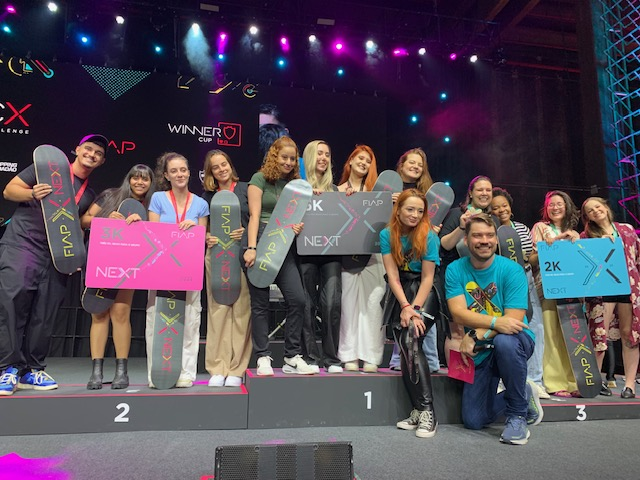

In [14]:
resultado = cv2.imread('/content/IMG_6394.jpg')
cv2_imshow(resultado)

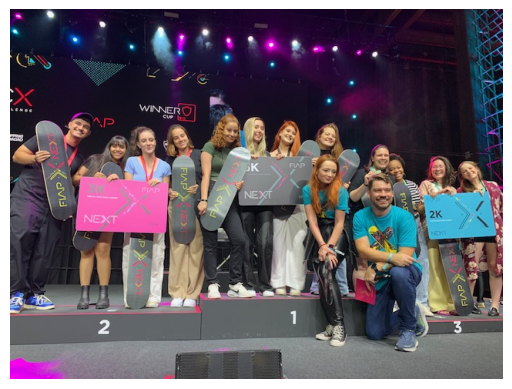

In [17]:
# Carregar a imagem no Colab
image_path = '/content/IMG_6394.jpg'

# Usar OpenCV para ler a imagem em cores (BGR por padrão no OpenCV)
image = cv2.imread(image_path)

# Exibir a imagem original
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))  # Converter de BGR para RGB para exibir corretamente
plt.axis('off')
plt.show()


In [32]:
# prompt: # Carregar o modelo YOLOv8 pré-treinado
# model = YOLO('/content/yolov8n.pt')  # Você pode usar yolov8s.pt, yolov8m.pt, etc., conforme a necessidade
# # Realizar a detecção de objetos na imagem
# results = model(image_path)
# # Exibir os resultados (a imagem com as detecções)
# results.show()

from ultralytics import YOLO
import matplotlib.pyplot as plt

# Carregar o modelo YOLOv8 pré-treinado
model = YOLO('/content/yolov8n.pt')  # Você pode usar yolov8s.pt, yolov8m.pt, etc., conforme a necessidade

# Realizar a detecção de objetos na imagem
# Ensure image_path is not a list
results = model(image_path)

# Access the Results object from the list if necessary
if isinstance(results, list):
    results = results[0]

# Exibir os resultados (a imagem com as detecções)
results.show()


image 1/1 /content/IMG_6394.jpg: 480x640 16 persons, 1 snowboard, 1 skateboard, 250.4ms
Speed: 6.7ms preprocess, 250.4ms inference, 3.4ms postprocess per image at shape (1, 3, 480, 640)


In [33]:
# Carregar o modelo YOLOv8 pré-treinado
model = YOLO('/content/yolov8n.pt')  # Você pode usar yolov8s.pt, yolov8m.pt, etc., conforme a necessidade

# Realizar a detecção de objetos na imagem
results = model(image_path)

# Access the Results object from the list
results = results[0]

# Exibir os resultados (a imagem com as detecções)
results.show()


image 1/1 /content/IMG_6394.jpg: 480x640 16 persons, 1 snowboard, 1 skateboard, 351.0ms
Speed: 3.9ms preprocess, 351.0ms inference, 2.1ms postprocess per image at shape (1, 3, 480, 640)


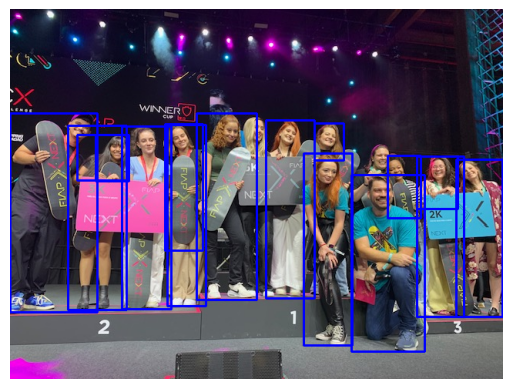

In [26]:
# YOLOv8 normalmente detecta pessoas na classe '0'
# Filtrar os resultados para desenhar retângulos ao redor dos rostos (pessoas)

# Filtrar e desenhar retângulos ao redor da classe 'pessoa' (classe 0)
for result in results:
    for box in result.boxes:
        cls = box.cls
        if int(cls) == 0:  # Classe '0' corresponde a 'pessoa'
            # Obter as coordenadas do retângulo de detecção
            x1, y1, x2, y2 = map(int, box.xyxy[0])
            # Desenhar um retângulo ao redor do rosto detectado (em azul)
            cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)

# Exibir a imagem com os rostos detectados
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))  # Converter de BGR para RGB para exibição correta
plt.axis('off')
plt.show()



image 1/1 /content/IMG_6394.jpg: 480x640 16 persons, 1 snowboard, 1 skateboard, 257.1ms
Speed: 5.6ms preprocess, 257.1ms inference, 2.0ms postprocess per image at shape (1, 3, 480, 640)


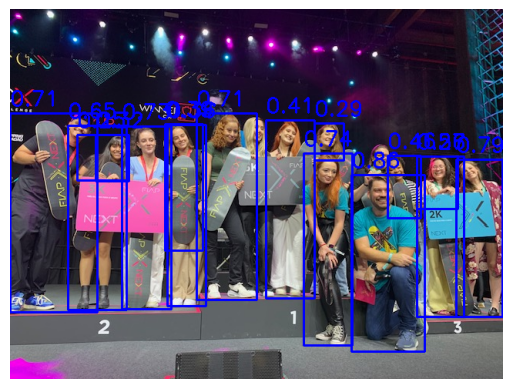

In [27]:
# Carregar o modelo YOLOv8 pré-treinado
model = YOLO('yolov8n.pt')  # Use qualquer versão YOLOv8 (nano, small, etc.)

# Realizar a detecção de objetos na imagem
results = model(image_path)

# Desenhar as detecções (com porcentagens de confiança)
for result in results:
    for box in result.boxes:
        cls = int(box.cls[0])  # Classe do objeto detectado
        conf = box.conf[0]  # Confiança da detecção
        if cls == 0:  # Classe '0' geralmente é 'pessoa' no YOLO
            # Coordenadas do retângulo
            x1, y1, x2, y2 = map(int, box.xyxy[0])
            # Desenhar um retângulo ao redor da detecção
            cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)
            # Adicionar a porcentagem de confiança na imagem
            text = f'{conf:.2f}'  # Formatar a confiança com duas casas decimais
            cv2.putText(image, text, (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 0, 0), 2)

# Exibir a imagem com detecções e porcentagens de confiança
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))  # Converter de BGR para RGB para exibir corretamente
plt.axis('off')
plt.show()


**Segmentação.**

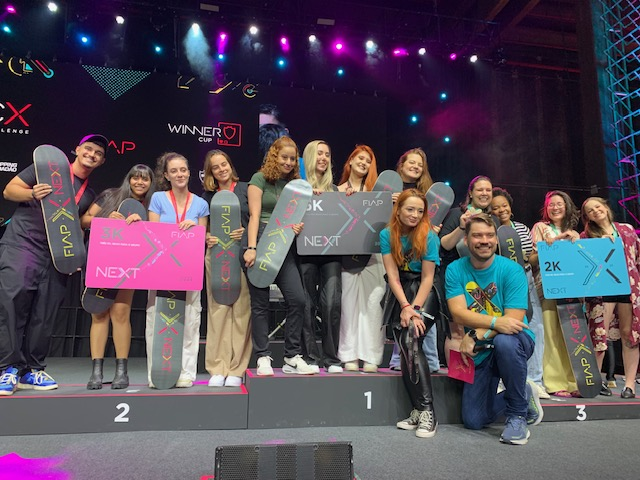

In [34]:
# prompt: resultado = cv2.imread('/content/yolov8n.pt')
# cv2_imshow(resultado)

import cv2
from google.colab.patches import cv2_imshow

try:
  resultado = cv2.imread('/content/IMG_6394.jpg')
  if resultado is None:
    print("Erro: O arquivo '/content/IMG_6394.jpg' não foi encontrado ou não pode ser lido como uma imagem.")
  else:
    cv2_imshow(resultado)
except Exception as e:
  print(f"Ocorreu um erro ao ler ou exibir a imagem: {e}")


**Imagem 2 -**

\



In [40]:
# Detecção a partir de arquivo externo:
!yolo task=detect mode=predict model=yolov8n.pt conf=0.25 source='https://img.freepik.com/fotos-premium/engrenagens-de-jogos-voadores-como-mouse-teclado-joystick-fone-de-ouvido-vr-microfone-3d-e-vetor-de-ilustracao_1262710-73111.jpg' save=True


Ultralytics YOLOv8.2.96 🚀 Python-3.10.12 torch-2.4.0+cu121 CPU (Intel Xeon 2.20GHz)
YOLOv8n summary (fused): 168 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs

100% 77.4k/77.4k [00:00<00:00, 347kB/s]
image 1/1 /content/engrenagens-de-jogos-voadores-como-mouse-teclado-joystick-fone-de-ouvido-vr-microfone-3d-e-vetor-de-ilustracao_1262710-73111.jpg: 640x640 1 mouse, 289.8ms
Speed: 8.6ms preprocess, 289.8ms inference, 2.4ms postprocess per image at shape (1, 3, 640, 640)
Results saved to runs/detect/predict3
💡 Learn more at https://docs.ultralytics.com/modes/predict


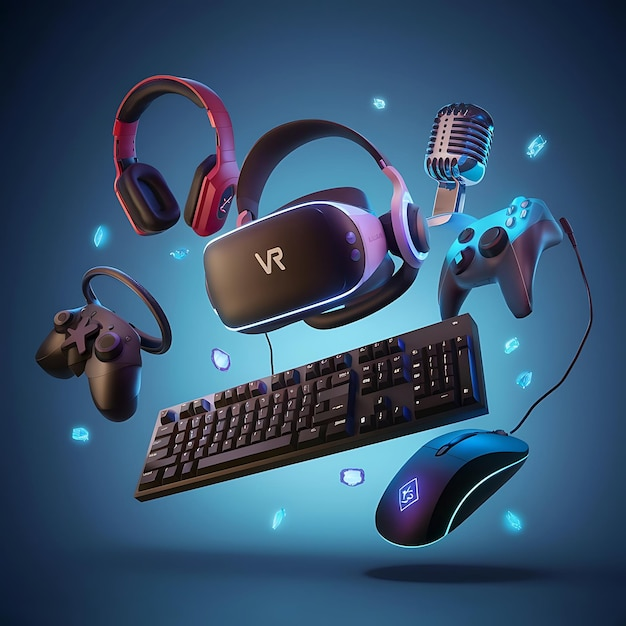

In [41]:
resultado = cv2.imread('/content/engrenagens-de-jogos-voadores-como-mouse-teclado-joystick-fone-de-ouvido-vr-microfone-3d-e-vetor-de-ilustracao_1262710-73111.jpg')
cv2_imshow(resultado)

In [45]:
# Carregar o modelo YOLOv8 pré-treinado para detecção
model = YOLO('yolov8n.pt')  # Ou 'yolov8s.pt', 'yolov8m.pt', etc.

# Realizar a detecção de objetos
results = model(img)



0: 640x640 1 traffic light, 2 mouses, 258.2ms
Speed: 5.3ms preprocess, 258.2ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)


In [46]:
# Assuming 'results' is a list and the first element is the detection result
results[0].show()

In [56]:
# Importar bibliotecas necessárias
import torch
from PIL import Image
import requests
from io import BytesIO
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Baixar a imagem
image_url = "https://img.freepik.com/fotos-premium/engrenagens-de-jogos-voadores-como-mouse-teclado-joystick-fone-de-ouvido-vr-microfone-3d-e-vetor-de-ilustracao_1262710-73111.jpg?w=826"
response = requests.get(image_url)
img = Image.open(BytesIO(response.content))

# Carregar o modelo YOLOv8 pré-treinado
model = YOLO('/content/yolov8n.pt')  # Ou 'yolov8s.pt', 'yolov8m.pt', etc.

# Realizar a detecção de objetos
# Removing the square brackets around model(img)
results = model(img)




0: 640x640 1 traffic light, 2 mouses, 438.1ms
Speed: 7.3ms preprocess, 438.1ms inference, 3.3ms postprocess per image at shape (1, 3, 640, 640)


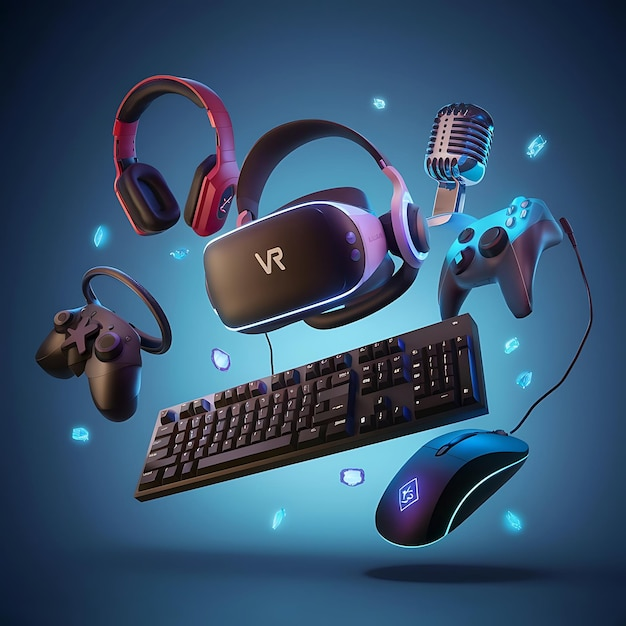

In [60]:
resultado = cv2.imread('/content/engrenagens-de-jogos-voadores-como-mouse-teclado-joystick-fone-de-ouvido-vr-microfone-3d-e-vetor-de-ilustracao_1262710-73111.jpg')
cv2_imshow(resultado)


WARNING ⚠️ Video stream unresponsive, please check your IP camera connection.
WARNING ⚠️ Video stream unresponsive, please check your IP camera connection.
WARNING ⚠️ Video stream unresponsive, please check your IP camera connection.
WARNING ⚠️ Video stream unresponsive, please check your IP camera connection.
WARNING ⚠️ Video stream unresponsive, please check your IP camera connection.
WARNING ⚠️ Video stream unresponsive, please check your IP camera connection.
WARNING ⚠️ Video stream unresponsive, please check your IP camera connection.
WARNING ⚠️ Video stream unresponsive, please check your IP camera connection.
WARNING ⚠️ Video stream unresponsive, please check your IP camera connection.
WARNING ⚠️ Video stream unresponsive, please check your IP camera connection.
WARNING ⚠️ Video stream unresponsive, please check your IP camera connection.
WARNING ⚠️ Video stream unresponsive, please check your IP camera connection.
0: 640x640 1 mouse, 1 keyboard, 1521.7ms
Speed: 22.1ms preproce

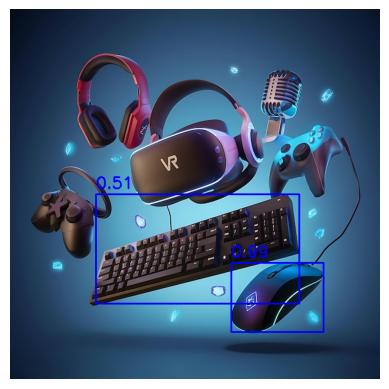

In [68]:
# Testar com uma imagem local
image_path = '/content/engrenagens-de-jogos-voadores-como-mouse-teclado-joystick-fone-de-ouvido-vr-microfone-3d-e-vetor-de-ilustracao_1262710-73111.jpg'
image_pil = Image.open(image_path)
image_cv2 = np.array(image_pil)
image_cv2 = cv2.cvtColor(image_cv2, cv2.COLOR_RGB2BGR)

# Realizar a detecção
results = model(image_cv2)

# Desenhar as detecções
for result in results:
    for box in result.boxes:
        cls = int(box.cls[0])
        conf = box.conf[0]
        if conf > 0.5:
            x1, y1, x2, y2 = map(int, box.xyxy[0])
            cv2.rectangle(image_cv2, (x1, y1), (x2, y2), (255, 0, 0), 2)
            text = f'{conf:.2f}'
            cv2.putText(image_cv2, text, (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 0, 0), 2)

plt.imshow(cv2.cvtColor(image_cv2, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()
